In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

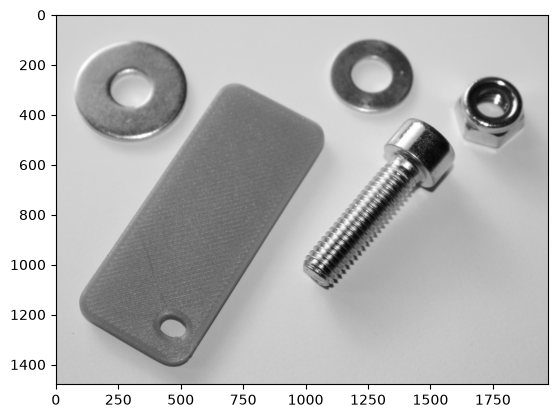

In [2]:
image = cv2.imread("image.jpg")
grayscale = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(grayscale, 'gray')

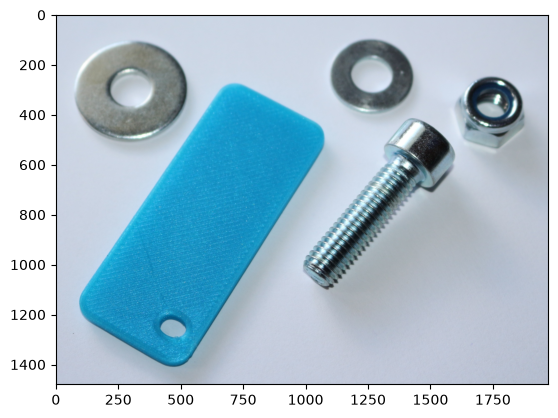

In [3]:
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))

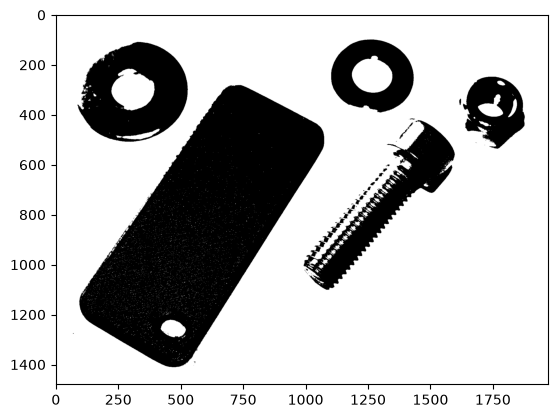

In [4]:
_, mask = cv2.threshold(
    grayscale,
    160,
    220,
    cv2.THRESH_BINARY
)

plt.imshow(mask, 'gray')


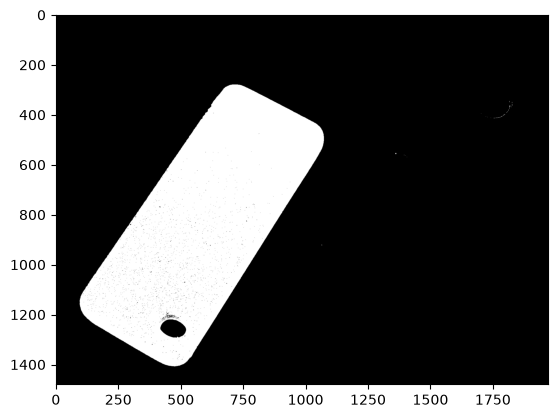

In [5]:
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

lower_blue = (95, 160, 100)
upper_blue = (105, 250, 250)

mask = cv2.inRange(
    hsv,
    lower_blue,
    upper_blue
)

plt.imshow(mask, 'gray')

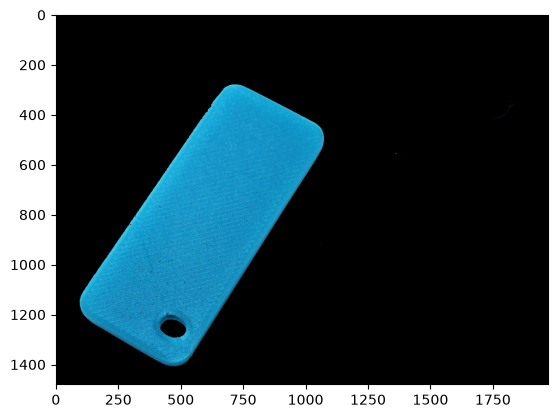

In [6]:
result = cv2.bitwise_and(image, image, mask=mask)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))

In [7]:
contours, _ = cv2.findContours(
    mask,
    cv2.RETR_TREE,
    cv2.CHAIN_APPROX_SIMPLE
)


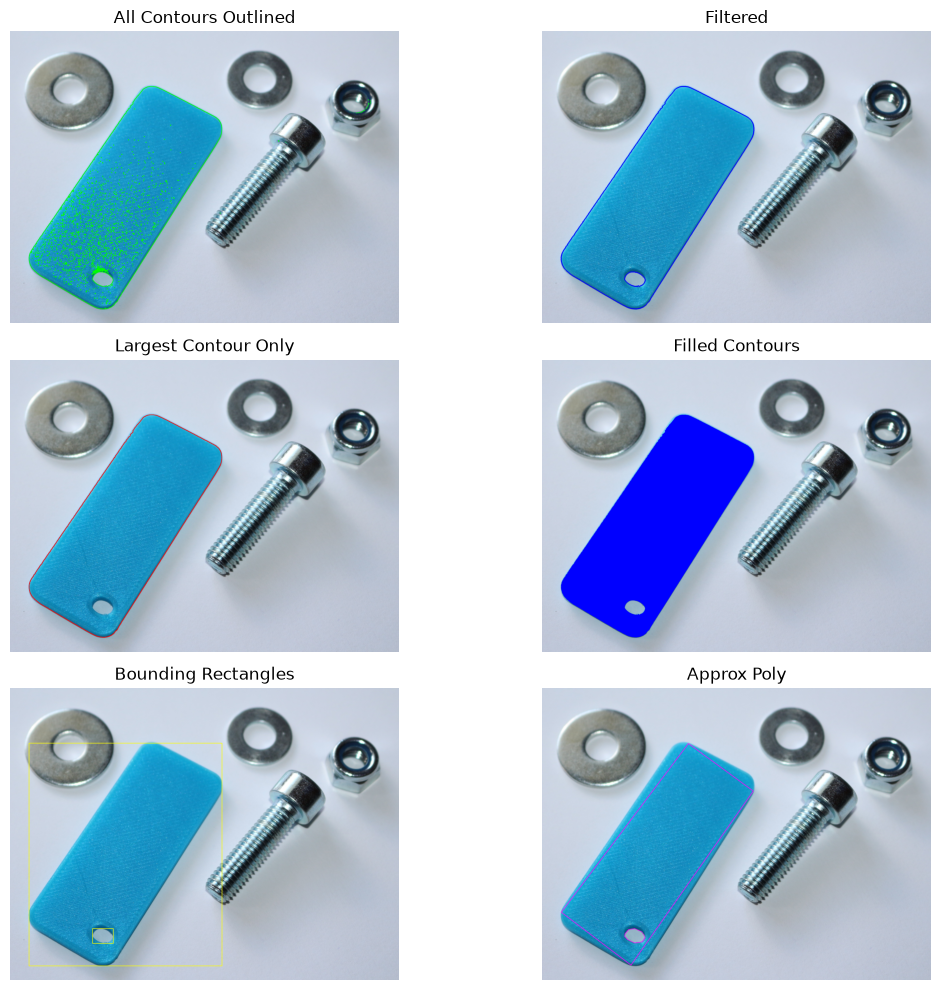

In [8]:
rgb_base = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# 1. Draw ALL contours
img_all = rgb_base.copy()
cv2.drawContours(img_all, contours, -1, (0, 255, 0), 2)  # Green outlines

# FILTER
# Set your minimum pixel area threshold (e.g., ignore shapes smaller than 500 pixels)
min_area = 500  

# Filter out small contours
filtered_contours = [cnt for cnt in contours if cv2.contourArea(cnt) > min_area]
img_filtered = rgb_base.copy()
cv2.drawContours(img_filtered, filtered_contours, -1, (0, 0, 255), 4)  # Green outlines

# 2. Draw only the LARGEST contour
img_largest = rgb_base.copy()
if contours:
    largest_contour = max(contours, key=cv2.contourArea)
    cv2.drawContours(img_largest, [largest_contour], -1, (255, 0, 0), 2)  # Red outline

# 3. Draw FILLED contours
img_filled = rgb_base.copy()
cv2.drawContours(img_filled, filtered_contours, -1, (0, 0, 255), cv2.FILLED)  # Blue fill

# 4. Draw BOUNDING BOXES around contours
img_boxes = rgb_base.copy()
for cnt in filtered_contours:
    x, y, w, h = cv2.boundingRect(cnt)
    cv2.rectangle(img_boxes, (x, y), (x + w, y + h), (255, 255, 0), 2)  # Yellow box

# -------------------------------------------------------------
# 5. Draw APPROXIMATED contours (cv2.approxPolyDP)
# -------------------------------------------------------------
img_approx = rgb_base.copy()
approx_contours = []

for cnt in filtered_contours:
    # Perimeter (arc length) used to set epsilon dynamically
    perimeter = cv2.arcLength(cnt, closed=True)
    
    # Epsilon determines accuracy tolerance (e.g., 2% of total perimeter)
    # Smaller values = closer to raw contour; Larger values = simpler polygon
    epsilon = 0.02 * perimeter
    
    # Approximate contour
    approx = cv2.approxPolyDP(cnt, epsilon, closed=True)
    approx_contours.append(approx)

cv2.drawContours(img_approx, approx_contours, -1, (255, 0, 255), 2)  # Magenta




# --- Display in Notebook using plt ---
fig, axes = plt.subplots(3, 2, figsize=(12, 10))

axes[0, 0].imshow(img_all)
axes[0, 0].set_title("All Contours Outlined")
axes[0, 0].axis('off')

axes[0, 1].imshow(img_filtered)
axes[0, 1].set_title("Filtered")
axes[0, 1].axis('off')

axes[1, 0].imshow(img_largest)
axes[1, 0].set_title("Largest Contour Only")
axes[1, 0].axis('off')

axes[1, 1].imshow(img_filled)
axes[1, 1].set_title("Filled Contours")
axes[1, 1].axis('off')

axes[2, 0].imshow(img_boxes)
axes[2, 0].set_title("Bounding Rectangles")
axes[2, 0].axis('off')

axes[2, 1].imshow(img_approx)
axes[2, 1].set_title("Approx Poly")
axes[2, 1].axis('off')


plt.tight_layout()
plt.show()

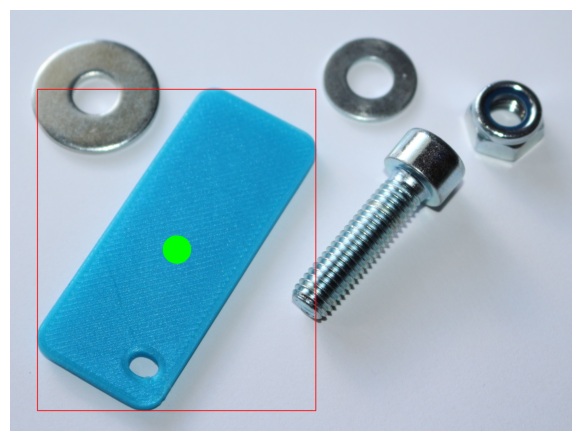

In [9]:
img_moments = rgb_base.copy()

largest_contour = max(contours, key=cv2.contourArea)

x, y, w, h = cv2.boundingRect(largest_contour)
M = cv2.moments(largest_contour)

cx = int(M["m10"] / M["m00"])
cy = int(M["m01"] / M["m00"])

cv2.rectangle(
    img_moments,
    (x, y),
    (x + w, y + h),
    (255, 0, 0),
    2
)

cv2.circle(
    img_moments,
    (cx, cy),
    50,
    (0, 255, 0),
    -1
)

plt.imshow(img_moments)
plt.tight_layout()
plt.axis('off')
plt.show()

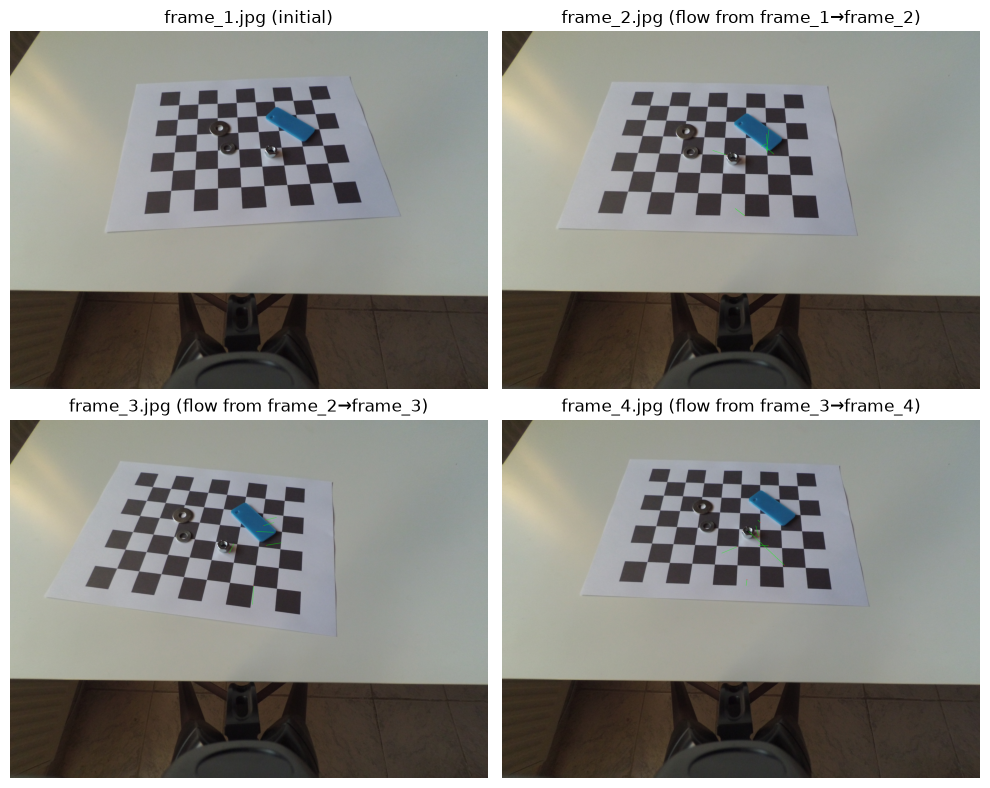

In [10]:
N_FRAMES = 4  # total frames to load (3 optical-flow steps)

# Image files are named frame_1.jpg, frame_2.jpg, frame_3.jpg, frame_4.jpg
image_paths = [f"frame_{i}.jpg" for i in range(1, N_FRAMES + 1)]

# --- Load N_FRAMES consecutive frames from disk ---
frames = []
for path in image_paths:
    frame = cv2.imread(path)
    if frame is None:
        raise FileNotFoundError(f"Could not read image: {path}")
    frames.append(frame)

# --- Track features across consecutive frame pairs ---
gray_frames = [cv2.cvtColor(f, cv2.COLOR_BGR2GRAY) for f in frames]

points = cv2.goodFeaturesToTrack(
    gray_frames[0],
    maxCorners=100,
    qualityLevel=0.3,
    minDistance=7
)

# annotated copies of each frame (BGR, will convert to RGB for display)
annotated = [f.copy() for f in frames]

for i in range(1, N_FRAMES):
    old_gray = gray_frames[i - 1]
    gray = gray_frames[i]

    new_points, status, error = cv2.calcOpticalFlowPyrLK(
        old_gray,
        gray,
        points,
        None
    )

    if new_points is None:
        break

    good_new = new_points[status == 1]
    good_old = points[status == 1]

    # draw on the CURRENT frame (i), showing motion since frame i-1
    for new, old in zip(good_new, good_old):
        x_new, y_new = new.ravel()
        x_old, y_old = old.ravel()
        cv2.line(
            annotated[i],
            (int(x_old), int(y_old)),
            (int(x_new), int(y_new)),
            (0, 255, 0),
            2
        )
        cv2.circle(
            annotated[i],
            (int(x_new), int(y_new)),
            3,
            (0, 0, 255),
            -1
        )

    points = good_new.reshape(-1, 1, 2)

# --- Visualize all frames in a grid with matplotlib ---
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()

for i, ax in enumerate(axes):
    if i < N_FRAMES:
        rgb = cv2.cvtColor(annotated[i], cv2.COLOR_BGR2RGB)
        ax.imshow(rgb)
        title = "frame_1.jpg (initial)" if i == 0 else f"frame_{i+1}.jpg (flow from frame_{i}\u2192frame_{i+1})"
        ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

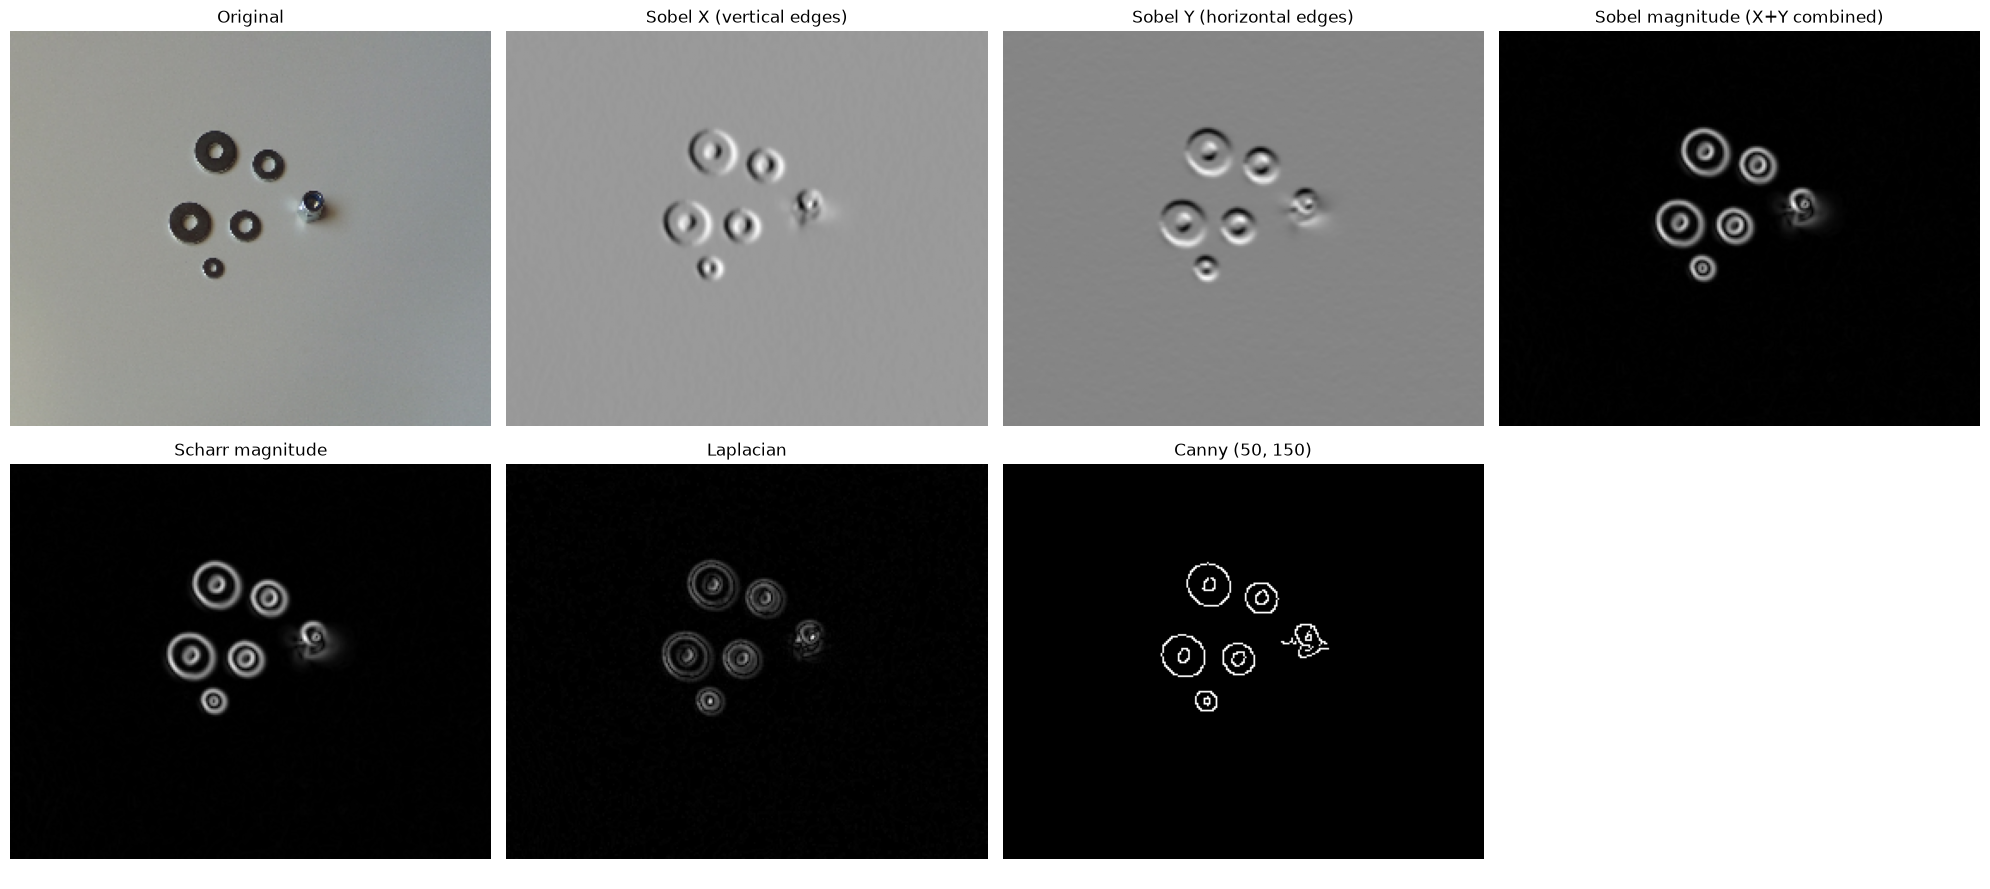

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_PATH = "frame_5_fixed.png"  # replace with your image path

# --- Load image ---
img = cv2.imread(IMAGE_PATH)
if img is None:
    raise FileNotFoundError(f"Could not read image: {IMAGE_PATH}")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (5, 5), 0)  # reduces noise so edge detectors don't fire on it

# --- Sobel: directional gradients (x, y separately, then combined magnitude) ---
sobel_x = cv2.Sobel(blur, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(blur, cv2.CV_64F, 0, 1, ksize=3)
sobel_mag = cv2.magnitude(sobel_x, sobel_y)
sobel_mag = np.uint8(np.clip(sobel_mag / sobel_mag.max() * 255, 0, 255))

# --- Scharr: like Sobel but a more accurate 3x3 kernel (better rotational symmetry) ---
scharr_x = cv2.Scharr(blur, cv2.CV_64F, 1, 0)
scharr_y = cv2.Scharr(blur, cv2.CV_64F, 0, 1)
scharr_mag = cv2.magnitude(scharr_x, scharr_y)
scharr_mag = np.uint8(np.clip(scharr_mag / scharr_mag.max() * 255, 0, 255))

# --- Laplacian: second derivative, highlights edges in all directions at once ---
laplacian = cv2.Laplacian(blur, cv2.CV_64F, ksize=3)
laplacian_abs = np.uint8(np.clip(np.abs(laplacian) / np.abs(laplacian).max() * 255, 0, 255))

# --- Canny: multi-stage (gradient + non-max suppression + hysteresis thresholding) ---
# thresholds are the two knobs that matter most — tune to your image's contrast
canny = cv2.Canny(blur, 50, 150)

# --- Visualize everything together ---
fig, axes = plt.subplots(2, 4, figsize=(20, 9))

axes[0, 0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
axes[0, 0].set_title("Original")

axes[0, 1].imshow(sobel_x, cmap="gray")
axes[0, 1].set_title("Sobel X (vertical edges)")

axes[0, 2].imshow(sobel_y, cmap="gray")
axes[0, 2].set_title("Sobel Y (horizontal edges)")

axes[0, 3].imshow(sobel_mag, cmap="gray")
axes[0, 3].set_title("Sobel magnitude (X+Y combined)")

axes[1, 0].imshow(scharr_mag, cmap="gray")
axes[1, 0].set_title("Scharr magnitude")

axes[1, 1].imshow(laplacian_abs, cmap="gray")
axes[1, 1].set_title("Laplacian")

axes[1, 2].imshow(canny, cmap="gray")
axes[1, 2].set_title("Canny (50, 150)")

axes[1, 3].axis("off")  # spare panel

for ax in axes.ravel():
    ax.axis("off") if ax not in (axes[1, 3],) else None

plt.tight_layout()
plt.show()

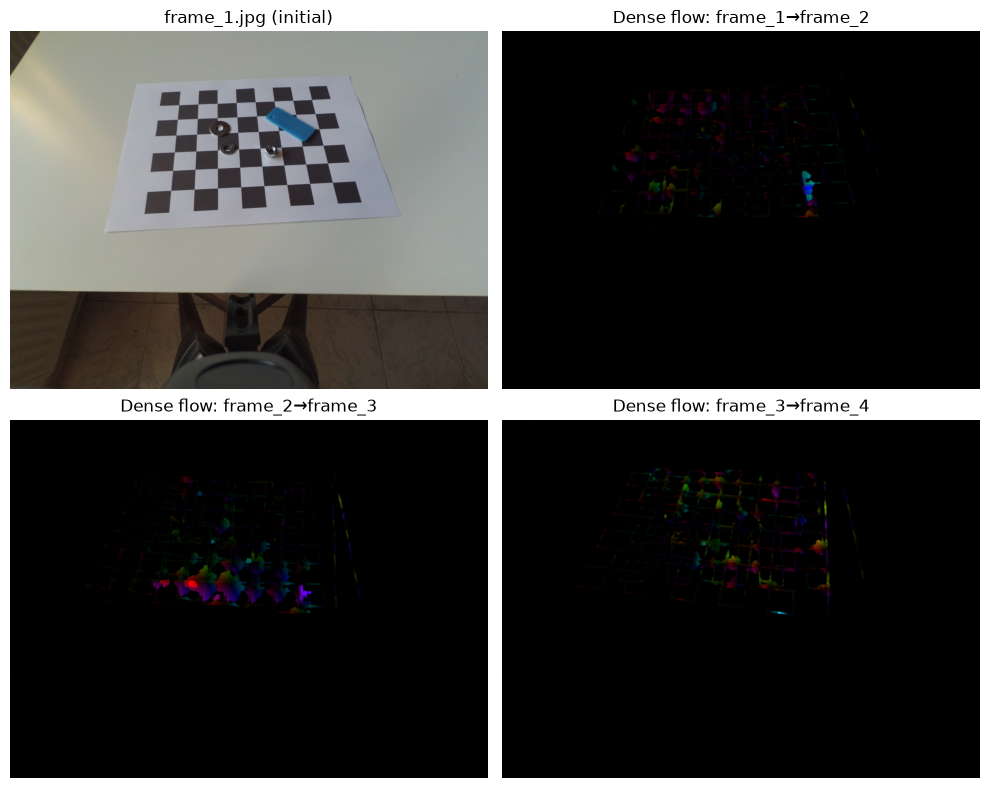

In [12]:
N_FRAMES = 4  # total frames to load (3 optical-flow steps)
 
# Image files are named frame_1.jpg, frame_2.jpg, frame_3.jpg, frame_4.jpg
image_paths = [f"frame_{i}.jpg" for i in range(1, N_FRAMES + 1)]
 
# --- Load N_FRAMES consecutive frames from disk ---
frames = []
for path in image_paths:
    frame = cv2.imread(path)
    if frame is None:
        raise FileNotFoundError(f"Could not read image: {path}")
    frames.append(frame)
 
gray_frames = [cv2.cvtColor(f, cv2.COLOR_BGR2GRAY) for f in frames]
 
# --- Compute dense optical flow (Farneback) across consecutive frame pairs ---
flow_vis = []  # RGB visualizations of each flow field
 
for i in range(1, N_FRAMES):
    old_gray = gray_frames[i - 1]
    gray = gray_frames[i]
 
    flow = cv2.calcOpticalFlowFarneback(
        old_gray,
        gray,
        None,
        0.5,
        3,
        15,
        3,
        5,
        1.2,
        0
    )
 
    # Convert flow (x, y) vectors -> HSV color map
    # hue = direction of motion, value = magnitude of motion
    magnitude, angle = cv2.cartToPolar(flow[..., 0], flow[..., 1])
 
    hsv = np.zeros((*gray.shape, 3), dtype=np.uint8)
    hsv[..., 0] = angle * 180 / np.pi / 2       # hue: 0-179 (OpenCV's range)
    hsv[..., 1] = 255                            # full saturation
    hsv[..., 2] = cv2.normalize(magnitude, None, 0, 255, cv2.NORM_MINMAX)
 
    bgr = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    flow_vis.append(rgb)
 
# --- Visualize: original first frame + 3 dense flow maps, in a 2x2 grid ---
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.ravel()
 
first_frame_rgb = cv2.cvtColor(frames[0], cv2.COLOR_BGR2RGB)
axes[0].imshow(first_frame_rgb)
axes[0].set_title("frame_1.jpg (initial)")
axes[0].axis("off")
 
for i, rgb in enumerate(flow_vis):
    ax = axes[i + 1]
    ax.imshow(rgb)
    ax.set_title(f"Dense flow: frame_{i+1}\u2192frame_{i+2}")
    ax.axis("off")
 
plt.tight_layout()
plt.show()
 

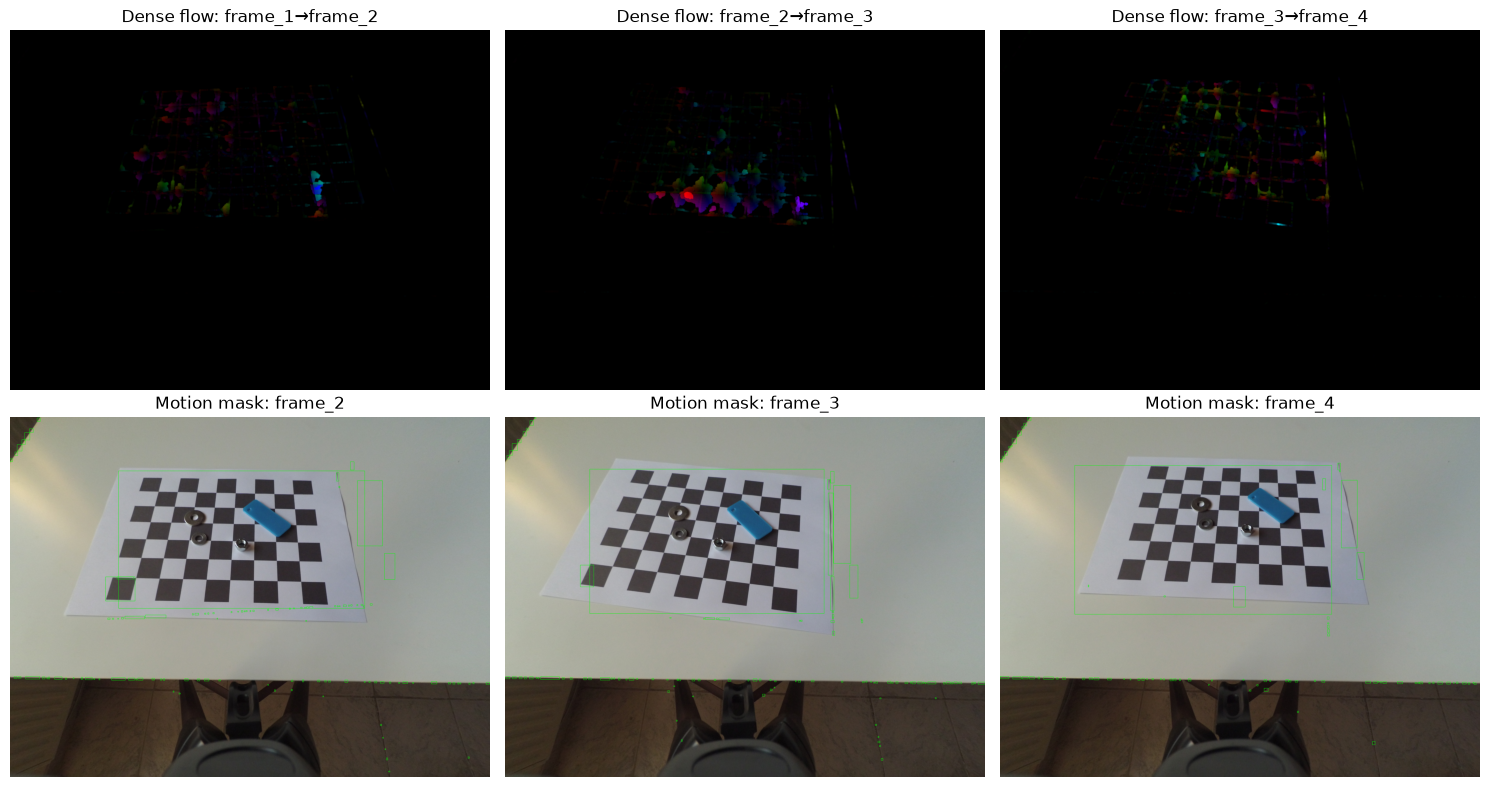

In [13]:
N_FRAMES = 4  # total frames to load (3 optical-flow steps)
MOTION_THRESHOLD = 2.0  # magnitude threshold for "this pixel moved" — tune to your noise floor
MIN_CONTOUR_AREA = 50   # ignore tiny noise blobs when drawing boxes

# Image files are named frame_1.jpg, frame_2.jpg, frame_3.jpg, frame_4.jpg
image_paths = [f"frame_{i}.jpg" for i in range(1, N_FRAMES + 1)]

# --- Load N_FRAMES consecutive frames from disk ---
frames = []
for path in image_paths:
    frame = cv2.imread(path)
    if frame is None:
        raise FileNotFoundError(f"Could not read image: {path}")
    frames.append(frame)

gray_frames = [cv2.cvtColor(f, cv2.COLOR_BGR2GRAY) for f in frames]

# --- Compute dense optical flow (Farneback) across consecutive frame pairs ---
flow_vis = []     # HSV-based RGB visualizations of each flow field
overlay_vis = []  # current frame with motion contours/boxes drawn on it

for i in range(1, N_FRAMES):
    old_gray = gray_frames[i - 1]
    gray = gray_frames[i]

    flow = cv2.calcOpticalFlowFarneback(
        old_gray,
        gray,
        None,
        0.5,
        3,
        15,
        3,
        5,
        1.2,
        0
    )

    magnitude, angle = cv2.cartToPolar(flow[..., 0], flow[..., 1])

    # --- HSV flow visualization ---
    hsv = np.zeros((*gray.shape, 3), dtype=np.uint8)
    hsv[..., 0] = angle * 180 / np.pi / 2       # hue: direction
    hsv[..., 1] = 255                            # full saturation
    hsv[..., 2] = cv2.normalize(magnitude, None, 0, 255, cv2.NORM_MINMAX)
    bgr = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
    flow_vis.append(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))

    # --- Motion mask: pixels whose flow magnitude exceeds the threshold ---
    motion_mask = (magnitude > MOTION_THRESHOLD).astype(np.uint8) * 255

    # Clean up the mask a bit (remove speckle noise, fill small gaps)
    kernel = np.ones((5, 5), np.uint8)
    motion_mask = cv2.morphologyEx(motion_mask, cv2.MORPH_OPEN, kernel)
    motion_mask = cv2.morphologyEx(motion_mask, cv2.MORPH_CLOSE, kernel)

    # --- Find moving-object contours and draw bounding boxes on the current frame ---
    contours, _ = cv2.findContours(
        motion_mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    overlay = frames[i].copy()
    for cnt in contours:
        if cv2.contourArea(cnt) < MIN_CONTOUR_AREA:
            continue
        x, y, w, h = cv2.boundingRect(cnt)
        cv2.rectangle(overlay, (x, y), (x + w, y + h), (0, 255, 0), 2)

    overlay_vis.append(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))

# --- Visualize: dense flow maps (top row) + motion-mask overlays (bottom row) ---
fig, axes = plt.subplots(2, N_FRAMES - 1, figsize=(5 * (N_FRAMES - 1), 8))

for i in range(N_FRAMES - 1):
    axes[0, i].imshow(flow_vis[i])
    axes[0, i].set_title(f"Dense flow: frame_{i+1}\u2192frame_{i+2}")
    axes[0, i].axis("off")

    axes[1, i].imshow(overlay_vis[i])
    axes[1, i].set_title(f"Motion mask: frame_{i+2}")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

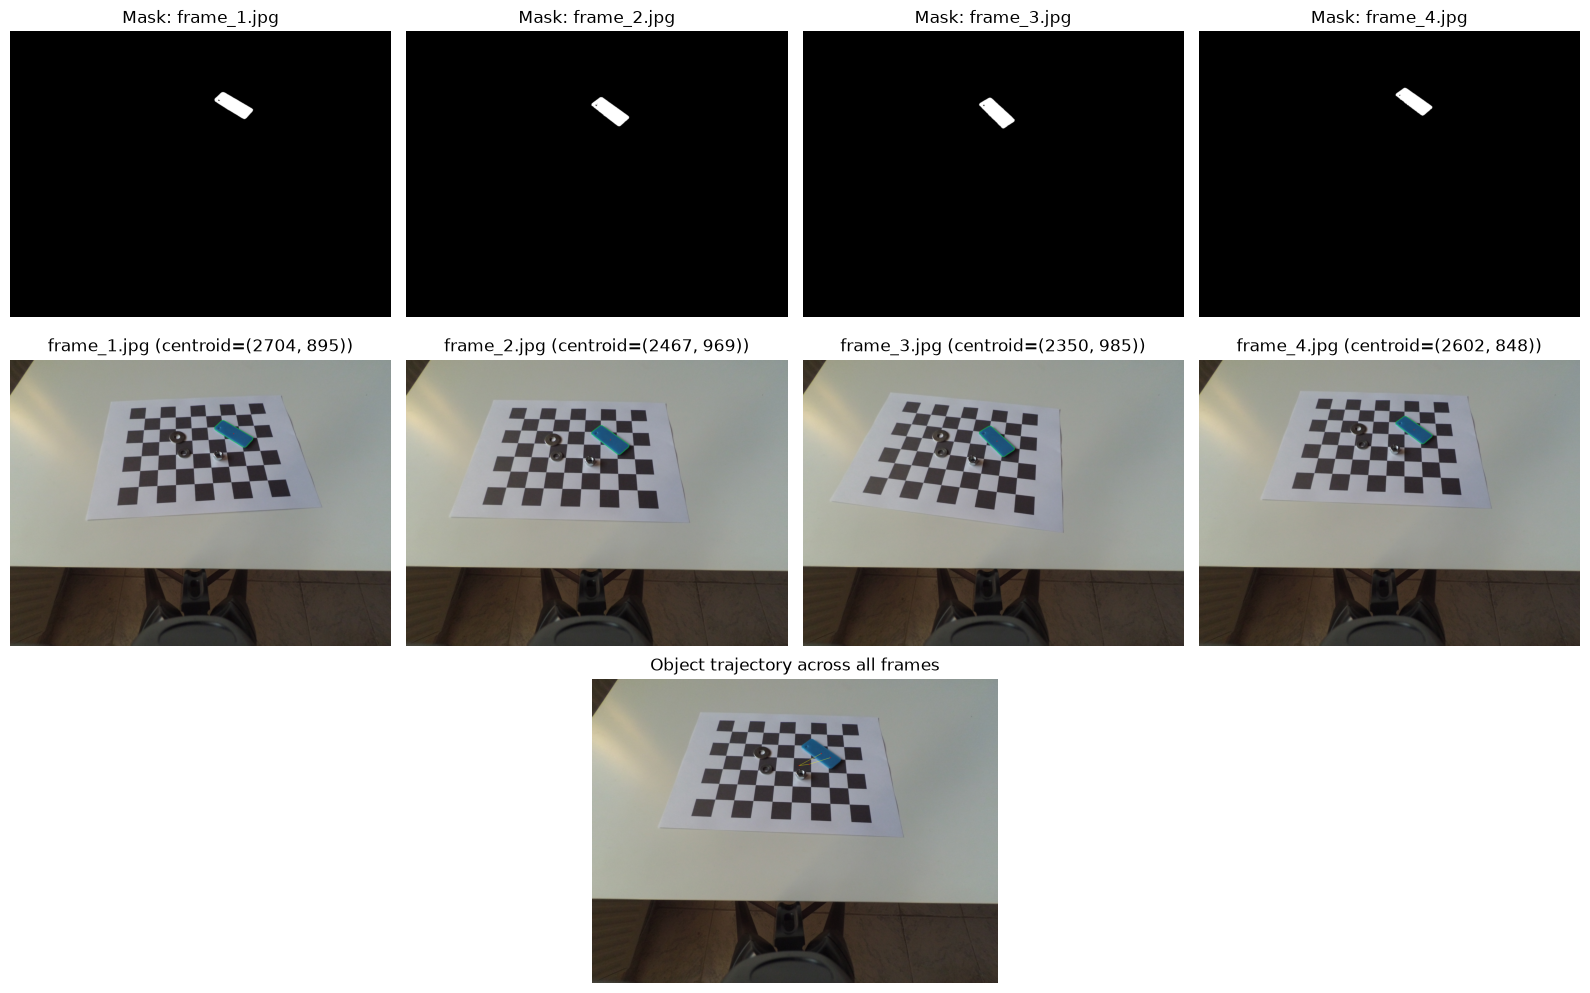

Centroids per frame:
  frame_1.jpg: (2704, 895)
  frame_2.jpg: (2467, 969)
  frame_3.jpg: (2350, 985)
  frame_4.jpg: (2602, 848)


In [14]:
N_FRAMES = 4

# Image files are named frame_1.jpg, frame_2.jpg, frame_3.jpg, frame_4.jpg
image_paths = [f"frame_{i}.jpg" for i in range(1, N_FRAMES + 1)]

lower_blue = (95, 160, 100)
upper_blue = (105, 250, 250)

MIN_CONTOUR_AREA = 50  # ignore tiny noise blobs

# --- Load frames ---
frames = []
for path in image_paths:
    frame = cv2.imread(path)
    if frame is None:
        raise FileNotFoundError(f"Could not read image: {path}")
    frames.append(frame)

# --- Detect the blue object in each frame ---
masks = []
centroids = []       # (x, y) center of the largest blue blob per frame, or None if not found
overlay_frames = []  # frames with contour + centroid drawn on them

for frame in frames:
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(hsv, lower_blue, upper_blue)

    # Clean up the mask a bit
    kernel = np.ones((5, 5), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    masks.append(mask)

    contours, _ = cv2.findContours(
        mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    overlay = frame.copy()
    centroid = None

    if contours:
        # track the largest blob as "the object"
        largest = max(contours, key=cv2.contourArea)
        if cv2.contourArea(largest) >= MIN_CONTOUR_AREA:
            M = cv2.moments(largest)
            cx = int(M["m10"] / M["m00"])
            cy = int(M["m01"] / M["m00"])
            centroid = (cx, cy)

            cv2.drawContours(overlay, [largest], -1, (0, 255, 0), 2)
            cv2.circle(overlay, centroid, 5, (0, 0, 255), -1)

    centroids.append(centroid)
    overlay_frames.append(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))

# --- Draw the trajectory (path of centroids) on the last frame ---
trajectory_frame = frames[-1].copy()
valid_centroids = [c for c in centroids if c is not None]

for i in range(1, len(valid_centroids)):
    cv2.line(trajectory_frame, valid_centroids[i - 1], valid_centroids[i], (0, 255, 255), 2)
for c in valid_centroids:
    cv2.circle(trajectory_frame, c, 5, (0, 0, 255), -1)

trajectory_rgb = cv2.cvtColor(trajectory_frame, cv2.COLOR_BGR2RGB)

# --- Visualize: mask + detection overlay for each frame, plus trajectory ---
fig, axes = plt.subplots(3, N_FRAMES, figsize=(4 * N_FRAMES, 10))

for i in range(N_FRAMES):
    axes[0, i].imshow(masks[i], cmap="gray")
    axes[0, i].set_title(f"Mask: frame_{i+1}.jpg")
    axes[0, i].axis("off")

    axes[1, i].imshow(overlay_frames[i])
    label = f"centroid={centroids[i]}" if centroids[i] else "not detected"
    axes[1, i].set_title(f"frame_{i+1}.jpg ({label})")
    axes[1, i].axis("off")

# trajectory spans the whole bottom row
for ax in axes[2, :]:
    ax.axis("off")
ax_traj = fig.add_subplot(3, 1, 3)
ax_traj.imshow(trajectory_rgb)
ax_traj.set_title("Object trajectory across all frames")
ax_traj.axis("off")

plt.tight_layout()
plt.show()

# --- Print numeric trajectory ---
print("Centroids per frame:")
for i, c in enumerate(centroids, start=1):
    print(f"  frame_{i}.jpg: {c}")

Found 6 objects


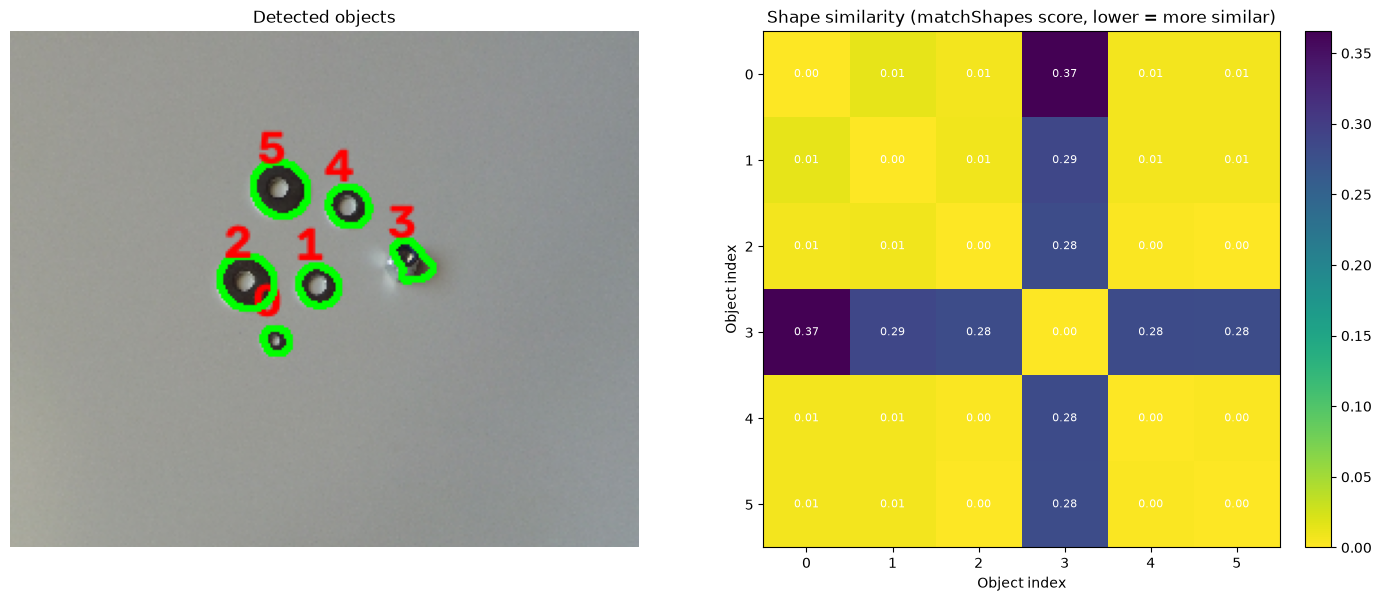


Closest shape match per object:
  Object 0 <-> Object 2  (score=0.0061)
  Object 1 <-> Object 4  (score=0.0062)
  Object 2 <-> Object 5  (score=0.0004)
  Object 3 <-> Object 2  (score=0.2807)
  Object 4 <-> Object 2  (score=0.0016)
  Object 5 <-> Object 2  (score=0.0004)


In [15]:
    import cv2
    import numpy as np
    import matplotlib.pyplot as plt
    
    IMAGE_PATH = "frame_5_fixed.png"  # replace with your image path
    MIN_CONTOUR_AREA = 50        # ignore tiny noise blobs
    
    # --- Load image and isolate objects from the background ---
    img = cv2.imread(IMAGE_PATH)
    if img is None:
        raise FileNotFoundError(f"Could not read image: {IMAGE_PATH}")
    
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (5, 5), 0)
    
    # Objects are darker than the light background, so THRESH_BINARY_INV
    # (Otsu picks the threshold automatically)
    _, thresh = cv2.threshold(
        blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )
    
    contours, _ = cv2.findContours(
        thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    contours = [c for c in contours if cv2.contourArea(c) >= MIN_CONTOUR_AREA]
    print(f"Found {len(contours)} objects")
    
    # --- Compute Hu moments for each object (for reference / inspection) ---
    hu_moments = []
    for c in contours:
        moments = cv2.moments(c)
        hu = cv2.HuMoments(moments).flatten()
        # log-scale Hu moments — raw values span many orders of magnitude
        hu_log = -np.sign(hu) * np.log10(np.abs(hu) + 1e-30)
        hu_moments.append(hu_log)
    
    # --- Pairwise shape comparison with matchShapes ---
    n = len(contours)
    scores = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            scores[i, j] = cv2.matchShapes(
                contours[i], contours[j], cv2.CONTOURS_MATCH_I1, 0.0
            )
    
    # --- Label each detected object on the image ---
    labeled = img.copy()
    centers = []
    for idx, c in enumerate(contours):
        M = cv2.moments(c)
        cx = int(M["m10"] / M["m00"])
        cy = int(M["m01"] / M["m00"])
        centers.append((cx, cy))
        cv2.drawContours(labeled, [c], -1, (0, 255, 0), 2)
        cv2.putText(
            labeled, str(idx), (cx - 10, cy - 10),
            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2
        )
    
    labeled_rgb = cv2.cvtColor(labeled, cv2.COLOR_BGR2RGB)
    
    # --- Visualize: labeled objects + similarity matrix heatmap ---
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    axes[0].imshow(labeled_rgb)
    axes[0].set_title("Detected objects")
    axes[0].axis("off")
    
    im = axes[1].imshow(scores, cmap="viridis_r")  # darker = more similar (lower score)
    axes[1].set_title("Shape similarity (matchShapes score, lower = more similar)")
    axes[1].set_xticks(range(n))
    axes[1].set_yticks(range(n))
    axes[1].set_xlabel("Object index")
    axes[1].set_ylabel("Object index")
    for i in range(n):
        for j in range(n):
            axes[1].text(
                j, i, f"{scores[i, j]:.2f}",
                ha="center", va="center", color="white", fontsize=8
            )
    fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
    
    plt.tight_layout()
    plt.show()
    
    # --- Print closest match for each object (excluding itself) ---
    print("\nClosest shape match per object:")
    for i in range(n):
        row = scores[i].copy()
        row[i] = np.inf  # exclude self-match
        j = int(np.argmin(row))
        print(f"  Object {i} <-> Object {j}  (score={row[j]:.4f})")

Found 6 objects


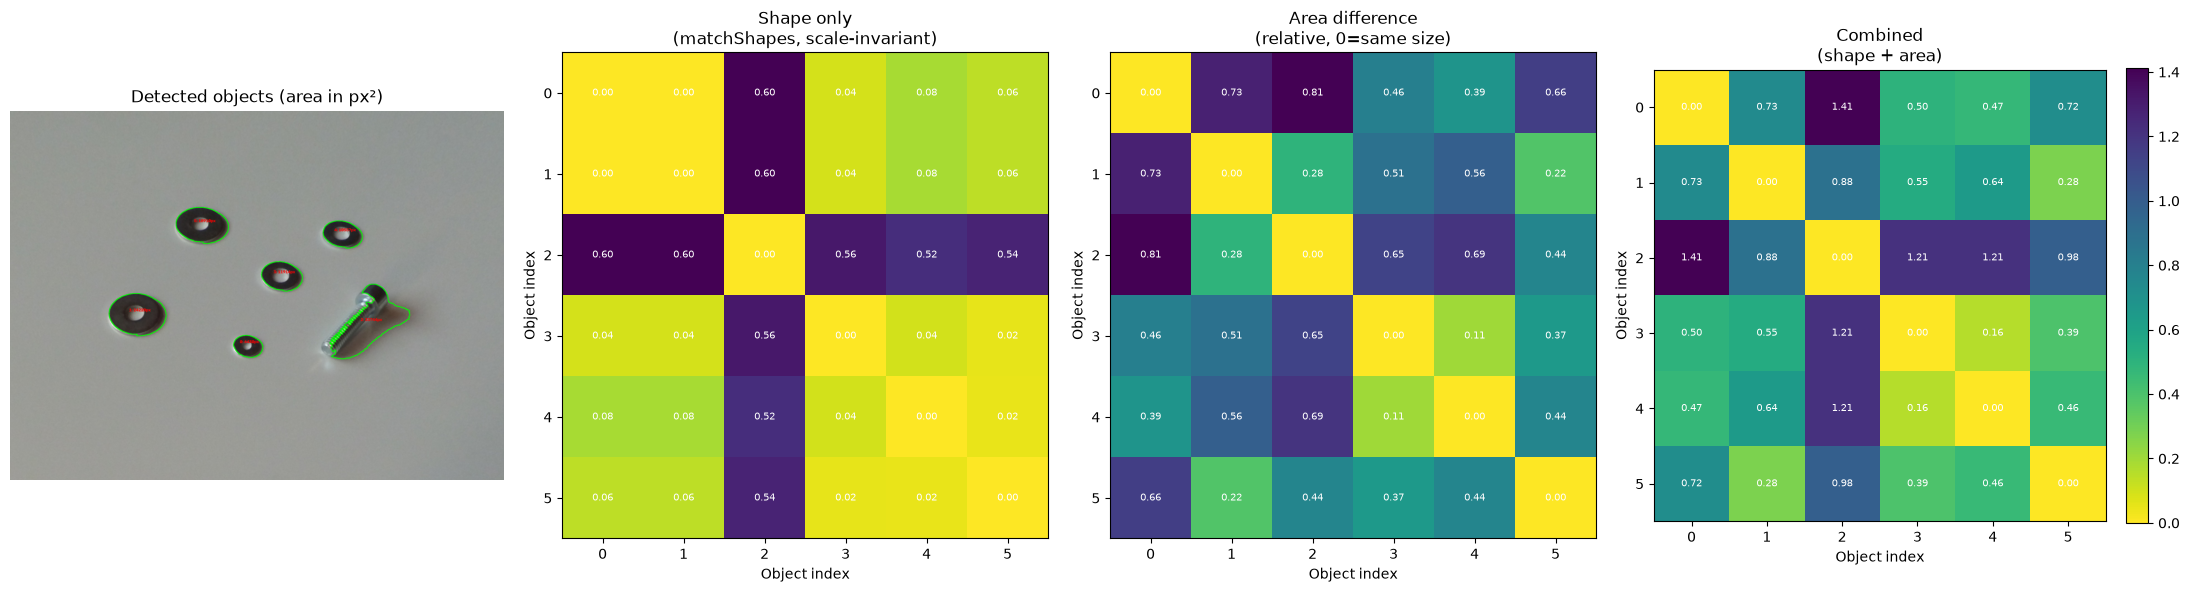


Closest match per object (shape + area combined):
  Object 0 (area=6430px) <-> Object 4 (area=10558px)  combined=0.4704  (shape=0.0795, area_diff=0.3910)
  Object 1 (area=24220px) <-> Object 5 (area=18910px)  combined=0.2787  (shape=0.0595, area_diff=0.2192)
  Object 2 (area=33744px) <-> Object 1 (area=24220px)  combined=0.8848  (shape=0.6026, area_diff=0.2822)
  Object 3 (area=11914px) <-> Object 4 (area=10558px)  combined=0.1554  (shape=0.0415, area_diff=0.1139)
  Object 4 (area=10558px) <-> Object 3 (area=11914px)  combined=0.1554  (shape=0.0415, area_diff=0.1139)
  Object 5 (area=18910px) <-> Object 1 (area=24220px)  combined=0.2787  (shape=0.0595, area_diff=0.2192)


In [16]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_PATH = "parts.jpg"  # replace with your image path
MIN_CONTOUR_AREA = 50             # ignore tiny noise blobs
AREA_WEIGHT = 1.0                 # how much area difference counts vs. shape (matchShapes) difference

# --- Load image and isolate objects from the background ---
img = cv2.imread(IMAGE_PATH)
if img is None:
    raise FileNotFoundError(f"Could not read image: {IMAGE_PATH}")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (5, 5), 0)

# Objects are darker than the light background, so THRESH_BINARY_INV
# (Otsu picks the threshold automatically)
_, thresh = cv2.threshold(
    blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

contours, _ = cv2.findContours(
    thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)
contours = [c for c in contours if cv2.contourArea(c) >= MIN_CONTOUR_AREA]
print(f"Found {len(contours)} objects")

# --- Compute area + Hu moments for each object ---
areas = np.array([cv2.contourArea(c) for c in contours])

hu_moments = []
for c in contours:
    moments = cv2.moments(c)
    hu = cv2.HuMoments(moments).flatten()
    # log-scale Hu moments — raw values span many orders of magnitude
    hu_log = -np.sign(hu) * np.log10(np.abs(hu) + 1e-30)
    hu_moments.append(hu_log)

# --- Pairwise shape comparison with matchShapes (this alone is scale-invariant,
# so a big washer and a small washer of the same style will score as "identical
# shape" even though they're clearly different-sized parts) ---
n = len(contours)
shape_scores = np.zeros((n, n))
for i in range(n):
    for j in range(n):
        shape_scores[i, j] = cv2.matchShapes(
            contours[i], contours[j], cv2.CONTOURS_MATCH_I1, 0.0
        )

# --- Pairwise area difference (relative, so it's comparable in scale to matchShapes
# scores instead of being in raw px^2, and symmetric regardless of which is larger) ---
area_diff = np.zeros((n, n))
for i in range(n):
    for j in range(n):
        area_diff[i, j] = abs(areas[i] - areas[j]) / max(areas[i], areas[j])

# --- Combined score: shape AND size both have to match for objects to be
# considered the same washer, not just the same "ring" style ---
combined_scores = shape_scores + AREA_WEIGHT * area_diff

# --- Label each detected object on the image (with its pixel area) ---
labeled = img.copy()
centers = []
for idx, c in enumerate(contours):
    M = cv2.moments(c)
    cx = int(M["m10"] / M["m00"])
    cy = int(M["m01"] / M["m00"])
    centers.append((cx, cy))
    cv2.drawContours(labeled, [c], -1, (0, 255, 0), 2)
    cv2.putText(
        labeled, f"{idx}: {int(areas[idx])}px", (cx - 30, cy - 10),
        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 2
    )

labeled_rgb = cv2.cvtColor(labeled, cv2.COLOR_BGR2RGB)


def _plot_heatmap(ax, matrix, title):
    im = ax.imshow(matrix, cmap="viridis_r")  # darker = more similar (lower score)
    ax.set_title(title)
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xlabel("Object index")
    ax.set_ylabel("Object index")
    for i in range(n):
        for j in range(n):
            ax.text(
                j, i, f"{matrix[i, j]:.2f}",
                ha="center", va="center", color="white", fontsize=7
            )
    return im


# --- Visualize: labeled objects + shape / area / combined similarity heatmaps ---
fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))

axes[0].imshow(labeled_rgb)
axes[0].set_title("Detected objects (area in px\u00b2)")
axes[0].axis("off")

im1 = _plot_heatmap(axes[1], shape_scores, "Shape only\n(matchShapes, scale-invariant)")
im2 = _plot_heatmap(axes[2], area_diff, "Area difference\n(relative, 0=same size)")
im3 = _plot_heatmap(axes[3], combined_scores, "Combined\n(shape + area)")

fig.colorbar(im3, ax=axes[3], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

# --- Print closest match for each object using the COMBINED score, so a match
# now means "same shape style AND same size" rather than just "same style" ---
print("\nClosest match per object (shape + area combined):")
for i in range(n):
    row = combined_scores[i].copy()
    row[i] = np.inf  # exclude self-match
    j = int(np.argmin(row))
    print(
        f"  Object {i} (area={areas[i]:.0f}px) <-> Object {j} (area={areas[j]:.0f}px)  "
        f"combined={row[j]:.4f}  (shape={shape_scores[i, j]:.4f}, area_diff={area_diff[i, j]:.4f})"
    )